# 01 — S&P 500 Data Preparation & Quality Check

### پروژه تحلیل اکتشافی بازارهای مالی

این Notebook فقط روی **دیتاست اصلی استاد/پروژه** تمرکز دارد و زنجیره‌ی `Extract → Clean → Validate → Transform` را نشان می‌دهد.

> نکته مهم: فایل خام ساختار Wide و چندسطحی دارد؛ 503 نماد برای هر کدام از پنج متغیر `Close / High / Low / Open / Volume` تکرار شده‌اند. برای ساخت شاخص بازار، فقط بلوک `Close` استفاده می‌شود؛ بنابراین قیمت، حجم و OHLC با هم قاطی نمی‌شوند.

## 1) هدف و سؤال‌ها
- ساختار واقعی فایل چیست؟
- چند نماد و چند متغیر داریم؟
- Missing Value و داده‌ی نامعتبر کجاست؟
- آیا تاریخ‌ها تکراری یا نامعتبر هستند؟
- چگونه یک نماینده‌ی شفاف از عملکرد جمعی سهام بسازیم؟

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
sns.set_theme(style="whitegrid")

DATA_PATHS=[Path("../data/SnP_daily_update.csv"), Path("data/SnP_daily_update.csv"), Path("SnP_daily_update.csv")]
DATA_PATH=next((p for p in DATA_PATHS if p.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("SnP_daily_update.csv not found. Put the original CSV in data/.")

raw=pd.read_csv(DATA_PATH, header=None, low_memory=False)
print(f"Raw shape: {raw.shape[0]:,} rows × {raw.shape[1]:,} columns")
display(raw.iloc[:4,:12])

Raw shape: 4,236 rows × 2,516 columns


,0,1,2,3,4,5,6,7,8,9,10,11
0,Price,Close,Close,Close,Close,Close,Close,Close,Close,Close,Close,Close
1,Ticker,A,AAPL,ABBV,ABNB,ABT,ACGL,ACN,ADBE,ADI,ADM,ADP
2,Date,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2010-01-04,19.743518829345703,6.400961399078369,NaN,NaN,17.968196868896484,7.60190486907959,30.610767364501953,37.09000015258789,21.703710556030273,20.02928352355957,25.1683349609375


## 2) استخراج متادیتا و بازسازی بلوک Close
ردیف اول نام متغیر، ردیف دوم ticker و ردیف سوم برچسب Date است. مشاهده‌های واقعی از ردیف چهارم شروع می‌شوند.

In [2]:
metric=raw.iloc[0,1:].astype(str)
ticker=raw.iloc[1,1:].astype(str)

metric_counts=metric.value_counts().rename_axis("Metric").to_frame("Count")
display(metric_counts)

expected_metrics={"Close","High","Low","Open","Volume"}
assert expected_metrics.issubset(set(metric)), "Expected OHLCV blocks were not found."

close_mask=metric.eq("Close")
close_idx=np.where(close_mask)[0]
close=raw.iloc[3:, [0]+list(close_idx)].copy()
close.columns=["Date"]+ticker[close_mask].tolist()
close["Date"]=pd.to_datetime(close["Date"], errors="coerce")
for c in close.columns[1:]:
    close[c]=pd.to_numeric(close[c], errors="coerce")
close=close.sort_values("Date").drop_duplicates("Date").reset_index(drop=True)

print("Close-only shape:", close.shape)
print("Date range:", close.Date.min().date(), "to", close.Date.max().date())
print("Unique Close tickers:", close.shape[1]-1)
assert close.columns[1:].is_unique
assert close.Date.notna().all()

,Count
Metric,
Close,503
High,503
Low,503
Open,503
Volume,503


Close-only shape: (4233, 504)
Date range: 2010-01-04 to 2026-10-30
Unique Close tickers: 503


## 3) Data Quality — Missing, Duplicate و مقادیر نامعتبر

Duplicate dates: 0
Invalid dates: 0
Non-positive Close values: 0


,missing_%
A,100.00
VZ,99.48
HOOD,97.71
FE,97.40
QCOM,93.98
SNPS,89.82
GILD,84.60
SPG,84.57
REG,84.50
VMC,81.76


,coverage
count,503.000000
mean,0.933613
std,0.187732
min,0.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,1.000000


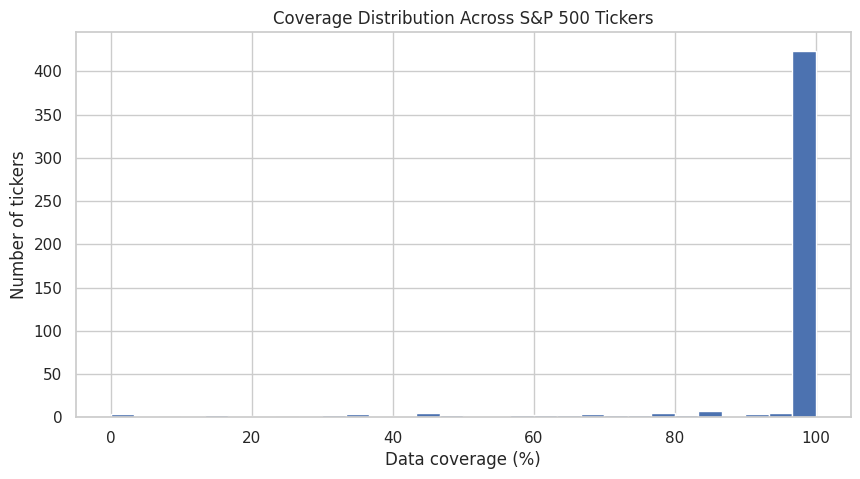

In [3]:
missing_pct=(close.iloc[:,1:].isna().mean()*100).sort_values(ascending=False)
quality=pd.DataFrame({"missing_%":missing_pct.round(2)})
print("Duplicate dates:", close.Date.duplicated().sum())
print("Invalid dates:", close.Date.isna().sum())
print("Non-positive Close values:", int((close.iloc[:,1:]<=0).sum().sum()))
display(quality.head(15))

coverage=1-close.iloc[:,1:].isna().mean()
coverage_summary=coverage.describe().to_frame("coverage")
display(coverage_summary)

plt.figure(figsize=(10,5))
plt.hist(coverage*100,bins=30)
plt.xlabel("Data coverage (%)")
plt.ylabel("Number of tickers")
plt.title("Coverage Distribution Across S&P 500 Tickers")
plt.show()

## 4) انتخاب نمادهای با پوشش کافی
برای ساخت proxy، نمادهایی با حداقل 80٪ مشاهده معتبر نگه داشته می‌شوند. **Missingها را با قیمت جعلی پر نمی‌کنیم.** در عوض بازده هر سهم محاسبه و میانگین بازده‌های موجود گرفته می‌شود.

In [4]:
selected=coverage[coverage>=0.80].index.tolist()
print(f"Retained tickers (coverage >= 80%): {len(selected)} / {len(coverage)}")

prices=close.set_index("Date")[selected]
returns=prices.pct_change(fill_method=None)
market_return=returns.mean(axis=1, skipna=True).rename("SP500_Proxy_Return")
market_proxy=market_return.to_frame().reset_index()
market_proxy["SP500_Proxy_Index"]=(1+market_proxy["SP500_Proxy_Return"].fillna(0)).cumprod()*100

display(market_proxy.head())
display(returns[selected].describe().T[["count","mean","std","min","max"]].sort_values("std",ascending=False).head(10))

Retained tickers (coverage >= 80%): 445 / 503


,Date,SP500_Proxy_Return,SP500_Proxy_Index
0,2010-01-04,NaN,100.000000
1,2010-01-05,0.003566,100.356613
2,2010-01-06,0.003028,100.660522
3,2010-01-07,0.005454,101.209538
4,2010-01-08,0.002511,101.463717


,count,mean,std,min,max
SNA,4232.0,0.001609,0.040294,-0.411215,0.359363
TSN,4110.0,0.001991,0.036034,-0.210628,0.243951
AME,4232.0,0.001568,0.035870,-0.242291,0.522901
NDAQ,3466.0,0.000515,0.034953,-0.357951,0.421923
FTNT,4232.0,0.000631,0.034027,-0.253322,0.455251
COIN,4232.0,0.001133,0.032389,-0.298660,0.230913
NCLH,4232.0,0.001556,0.031970,-0.198185,0.234432
AXP,4232.0,0.001562,0.031661,-0.196740,0.286784
APD,4232.0,0.000434,0.031560,-0.538647,0.294664
FDS,4232.0,0.000659,0.031141,-0.203327,0.296846


## 5) بررسی توزیع بازده و نوسان
در داده‌های مالی، outlier الزاماً خطا نیست؛ ممکن است یک حرکت واقعی بازار باشد. بنابراین در این پروژه outlierها **شناسایی و تفسیر** می‌شوند، نه اینکه کورکورانه حذف شوند.

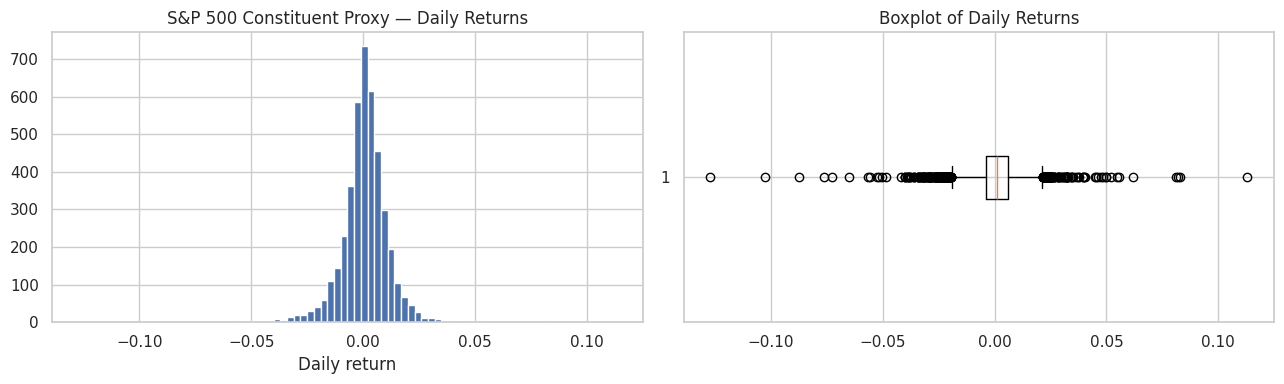

IQR bounds: -0.0193 to 0.0214
Potential outliers: 246
Annualized volatility: 0.17638692752192534


In [5]:
proxy_ret=market_proxy["SP500_Proxy_Return"].dropna()
fig,ax=plt.subplots(1,2,figsize=(13,4))
ax[0].hist(proxy_ret,bins=80)
ax[0].set_title("S&P 500 Constituent Proxy — Daily Returns")
ax[0].set_xlabel("Daily return")
ax[1].boxplot(proxy_ret,vert=False)
ax[1].set_title("Boxplot of Daily Returns")
plt.tight_layout(); plt.show()

q1,q3=proxy_ret.quantile([.25,.75]); iqr=q3-q1
lo,hi=q1-1.5*iqr,q3+1.5*iqr
print(f"IQR bounds: {lo:.4f} to {hi:.4f}")
print("Potential outliers:", int(((proxy_ret<lo)|(proxy_ret>hi)).sum()))
print("Annualized volatility:", float(proxy_ret.std()*np.sqrt(252)))

## 6) خروجی قابل استفاده برای Notebook دوم
این فایل کوچک جایگزین خواندن دوباره‌ی CSV سنگین در بخش cross-asset می‌شود.

In [6]:
OUT=Path("../data/sp500_market_proxy.csv")
if not OUT.parent.exists(): OUT=Path("data/sp500_market_proxy.csv")
market_proxy.to_csv(OUT,index=False)
print("Saved:", OUT.resolve())

Saved: /mnt/data/final_cross_asset_checked/data/sp500_market_proxy.csv


# جمع‌بندی Notebook 01
- فایل خام به‌درستی به بلوک‌های OHLCV تفکیک شد.
- فقط `Close` برای ساخت بازده و proxy استفاده شد.
- Missing Valueها بررسی شدند و حذف/پرکردن کورکورانه انجام نشد.
- کیفیت تاریخ‌ها و مقادیر مثبت قیمت کنترل شد.
- یک S&P 500 constituent proxy شفاف برای تحلیل cross-asset ساخته شد.

> این proxy **شاخص رسمی S&P 500 نیست**؛ یک میانگین بازدهی equal-weighted از constituentهای موجود در فایل است.